Importing all libraries

In [9]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
plt.style.use("fivethirtyeight")
import warnings
warnings.filterwarnings("ignore")

In [10]:
df = pd.read_csv("D:/mannu/ML/churn_predictor/data/Raw/Telco-Customer-Churn.csv")

In [11]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")


Number of Rows: 7043
Number of Columns: 21


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [14]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.drop(columns=['customerID'], inplace=True)

In [17]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [18]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [20]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [21]:
df["MonthlyCharges"].dtype

dtype('float64')

In [22]:
cat_col = ['gender', 'Partner', 'Dependents',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod','Churn']

for col in cat_col:
    print(f"{col}: {list(df[col].unique())}")
    print("---------------------------------")


gender: ['Female', 'Male']
---------------------------------
Partner: ['Yes', 'No']
---------------------------------
Dependents: ['No', 'Yes']
---------------------------------
PhoneService: ['No', 'Yes']
---------------------------------
MultipleLines: ['No phone service', 'No', 'Yes']
---------------------------------
InternetService: ['DSL', 'Fiber optic', 'No']
---------------------------------
OnlineSecurity: ['No', 'Yes', 'No internet service']
---------------------------------
OnlineBackup: ['Yes', 'No', 'No internet service']
---------------------------------
DeviceProtection: ['No', 'Yes', 'No internet service']
---------------------------------
TechSupport: ['No', 'Yes', 'No internet service']
---------------------------------
StreamingTV: ['No', 'Yes', 'No internet service']
---------------------------------
StreamingMovies: ['No', 'Yes', 'No internet service']
---------------------------------
Contract: ['Month-to-month', 'One year', 'Two year']
---------------------------

In [23]:
df = df.replace("No internet service", "No")
df = df.replace("No phone service", "No")


In [24]:
for col in df.columns:
    if col not in ['tenure', 'MonthlyCharges', 'TotalCharges']:
        print(col, list(df[col].unique()))
        print("***********************")

gender ['Female', 'Male']
***********************
SeniorCitizen [np.int64(0), np.int64(1)]
***********************
Partner ['Yes', 'No']
***********************
Dependents ['No', 'Yes']
***********************
PhoneService ['No', 'Yes']
***********************
MultipleLines ['No', 'Yes']
***********************
InternetService ['DSL', 'Fiber optic', 'No']
***********************
OnlineSecurity ['No', 'Yes']
***********************
OnlineBackup ['Yes', 'No']
***********************
DeviceProtection ['No', 'Yes']
***********************
TechSupport ['No', 'Yes']
***********************
StreamingTV ['No', 'Yes']
***********************
StreamingMovies ['No', 'Yes']
***********************
Contract ['Month-to-month', 'One year', 'Two year']
***********************
PaperlessBilling ['Yes', 'No']
***********************
PaymentMethod ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
***********************
Churn ['No', 'Yes']
***********************

In [25]:
#distribution plot analysis

def plot_distribution(df, column_name):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    sns.histplot(df[column_name], kde=True)
    plt.title(f"Distibution of {column_name}")

    plt.subplot(1,2,2)
    sns.boxplot(y=df[column_name])
    plt.title(f'Boxplot of {column_name}')

    plt.tight_layout()
    plt.show()

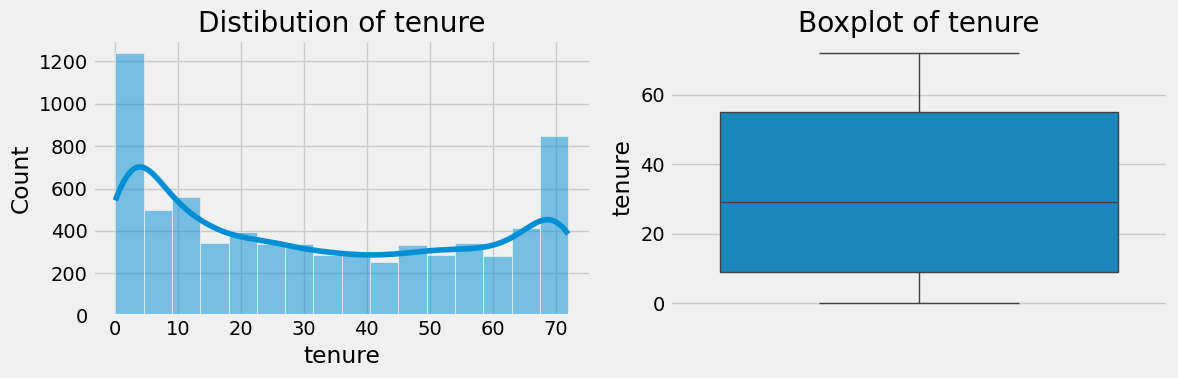

In [26]:
plot_distribution(df, "tenure")

In [27]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

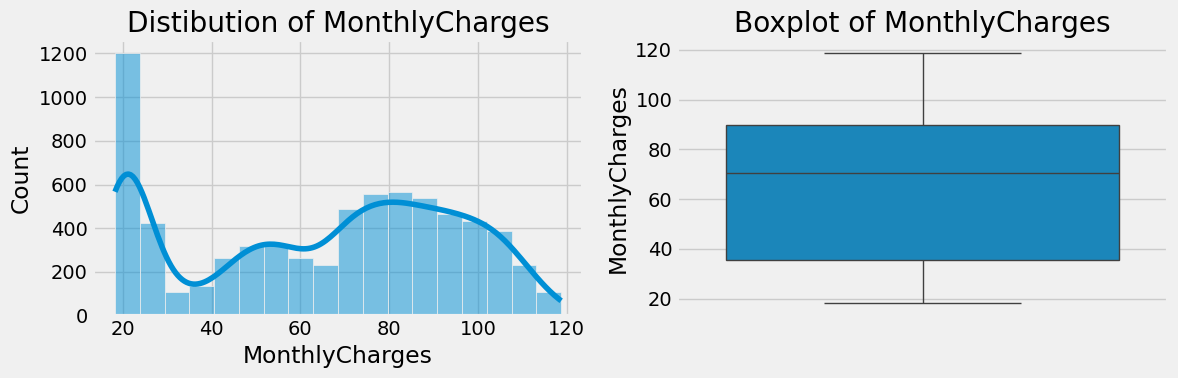

In [28]:
plot_distribution(df, "MonthlyCharges")

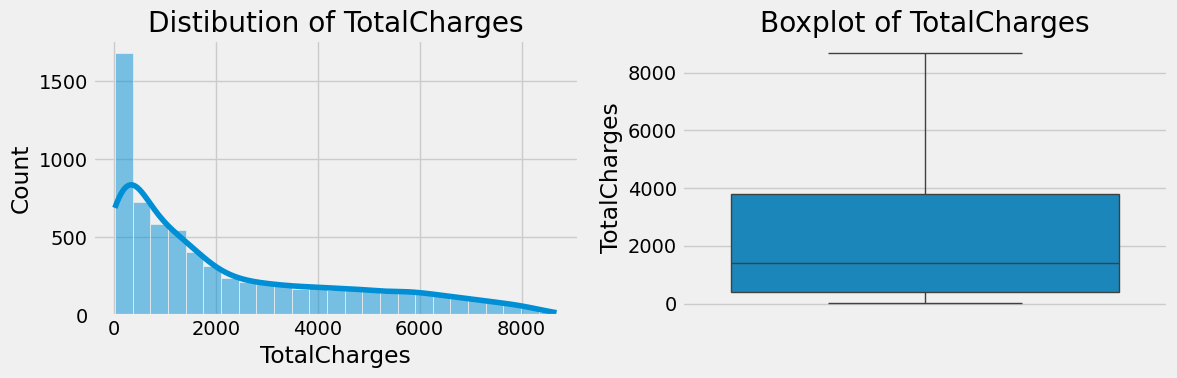

In [29]:
plot_distribution(df,"TotalCharges")

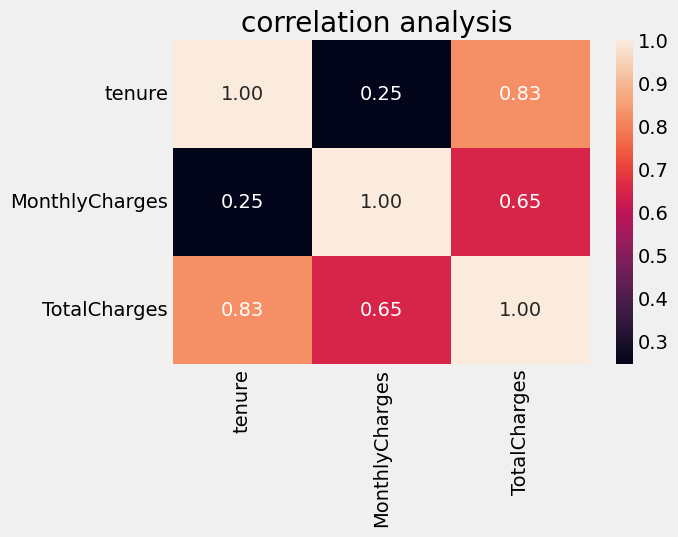

In [30]:
plt.figure(figsize=(6,4))
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr(), annot=True, fmt= ".2f")
plt.title("correlation analysis ")
plt.show()

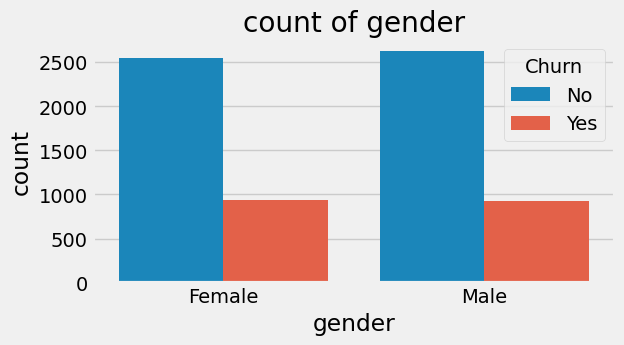

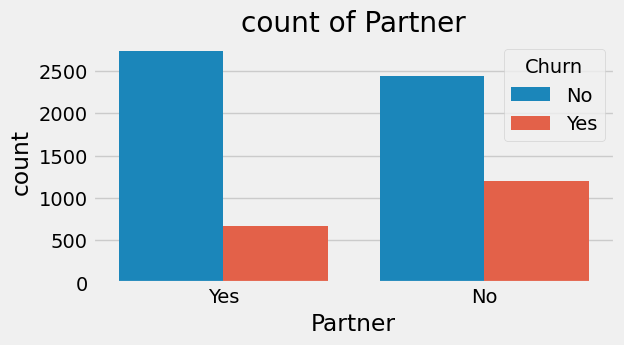

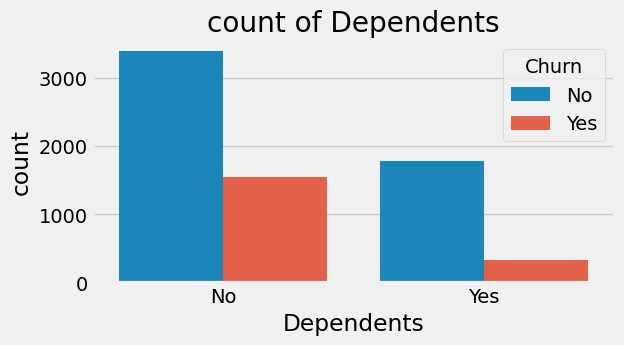

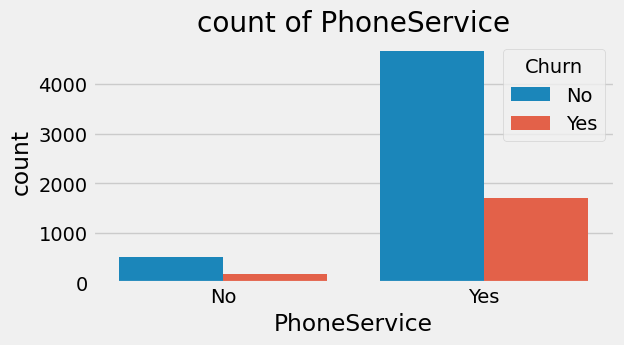

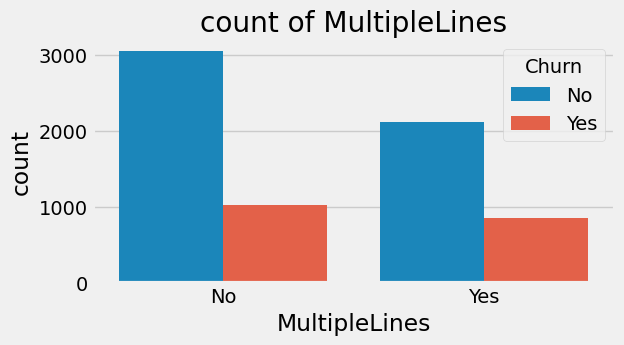

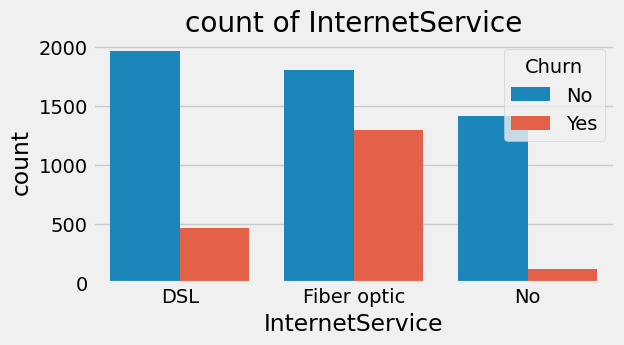

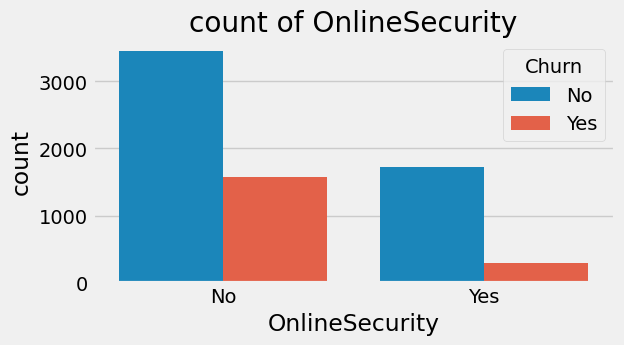

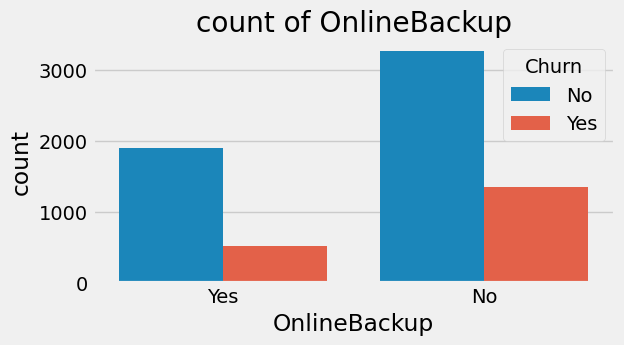

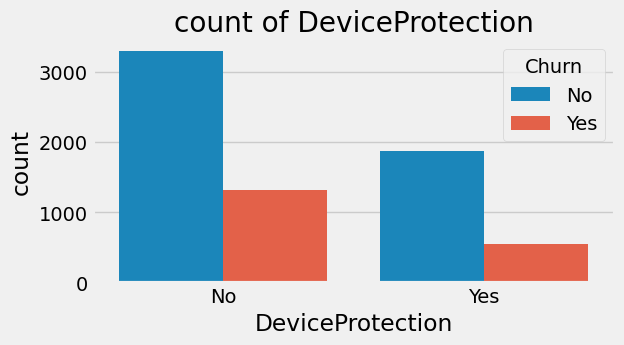

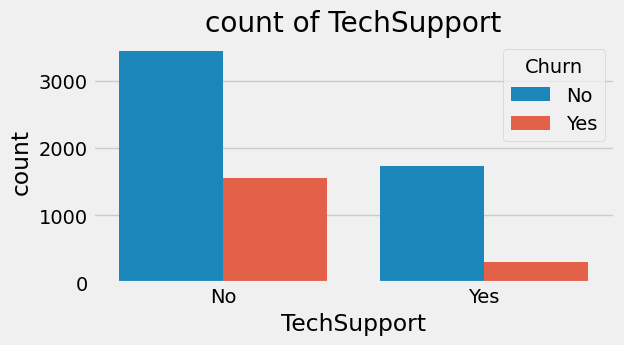

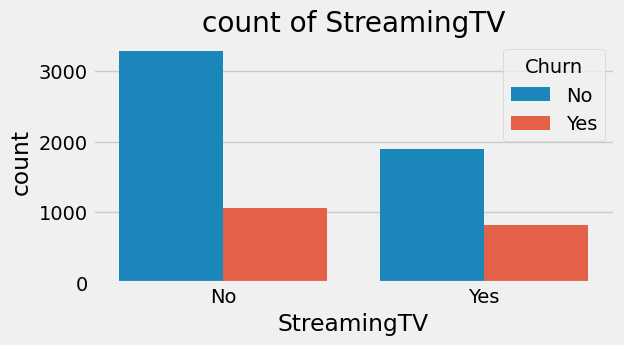

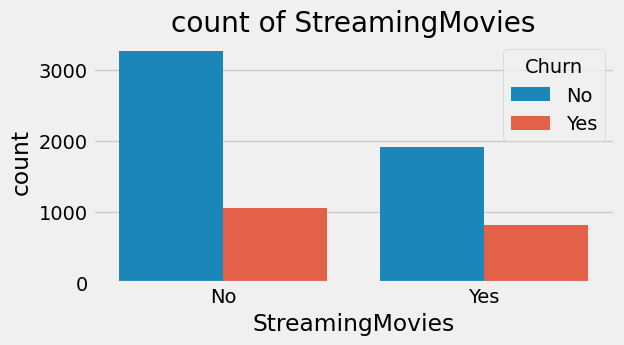

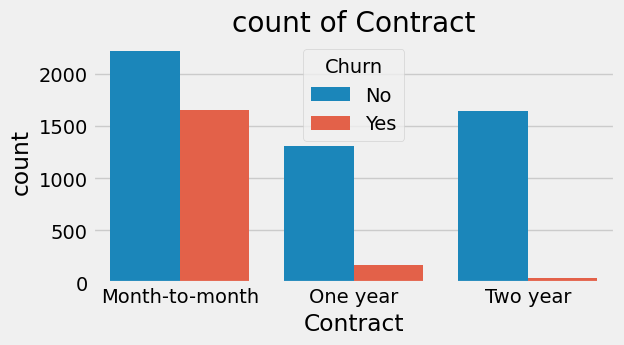

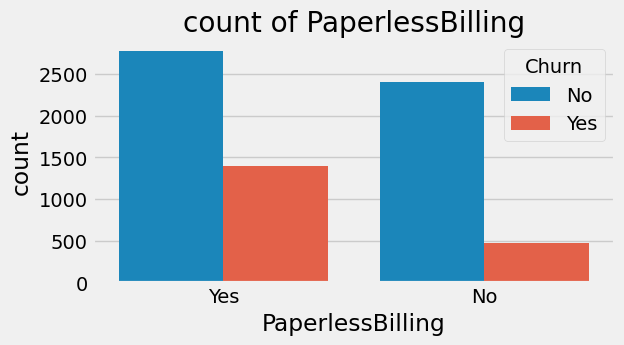

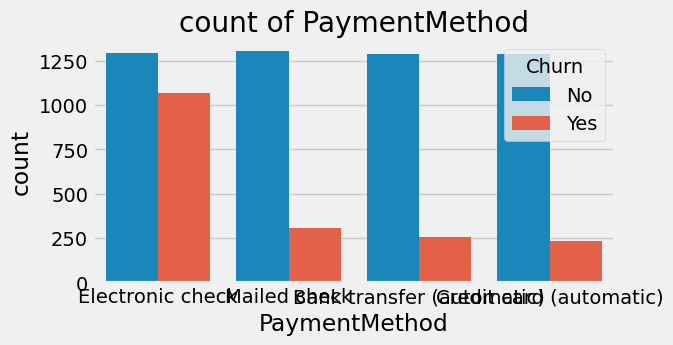

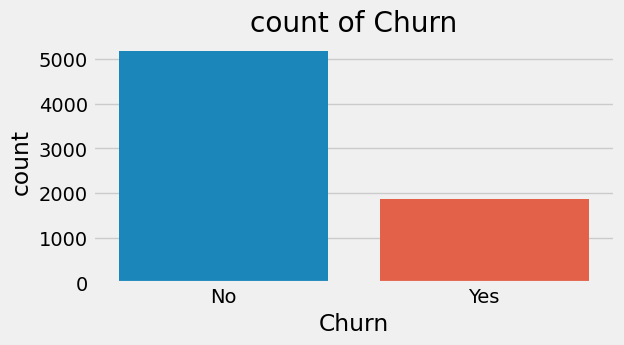

In [31]:
for col in cat_col:
    plt.figure(figsize=(6,3))
    sns.countplot(data=df,x=col ,hue='Churn')
    plt.title(f"count of {col}")
    plt.show()

In [32]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [33]:
df["Churn"] = df["Churn"].replace({"Yes":1, "No":0})

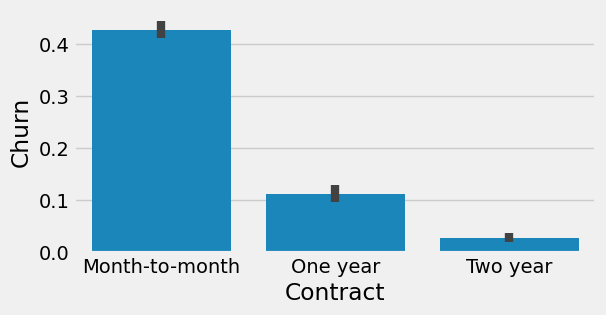

In [34]:
plt.figure(figsize=(6,3))
sns.barplot(data=df,  x="Contract", y="Churn")
plt.show()

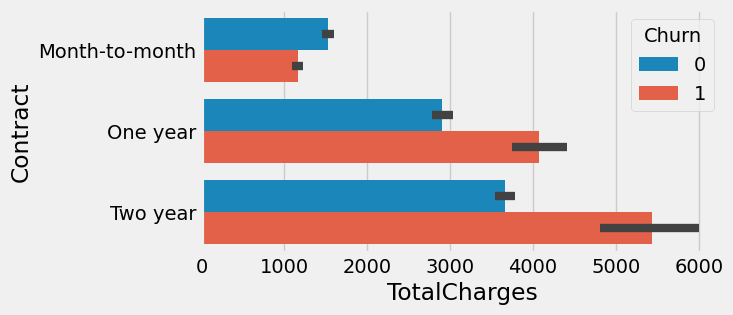

In [35]:
plt.figure(figsize=(6,3))
sns.barplot(data=df, x="TotalCharges", y="Contract", hue="Churn")
plt.show()

In [36]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

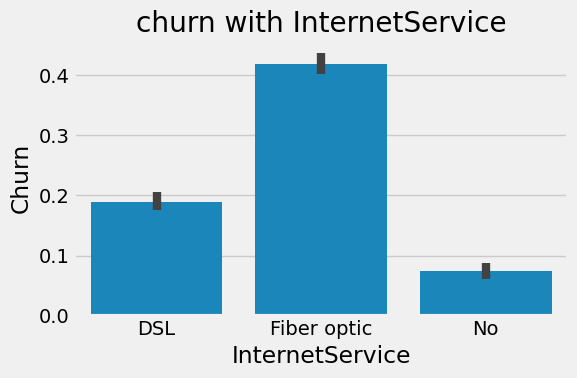

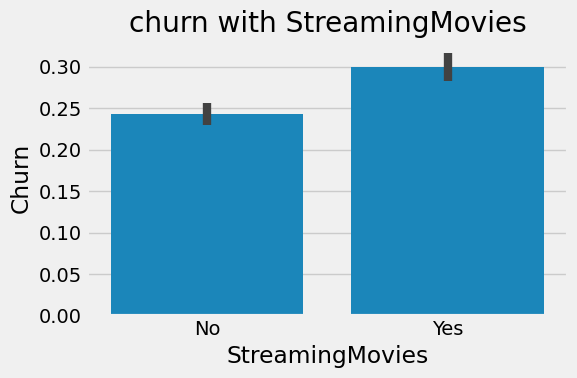

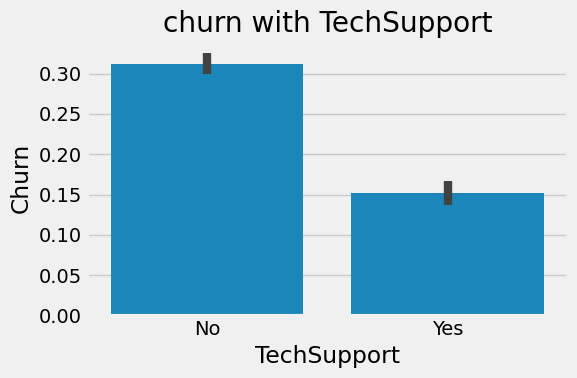

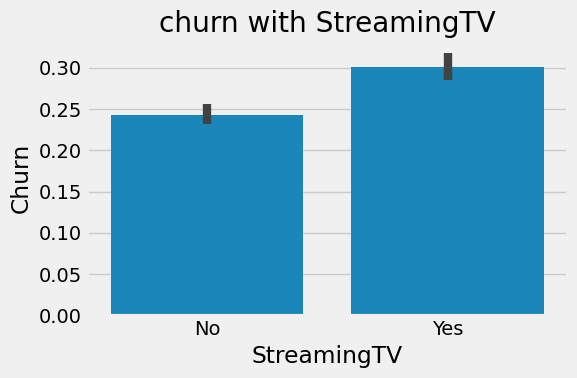

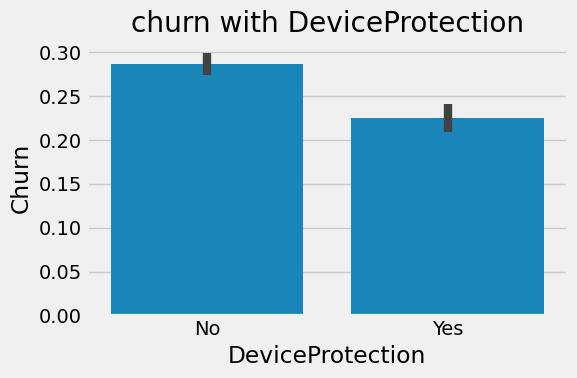

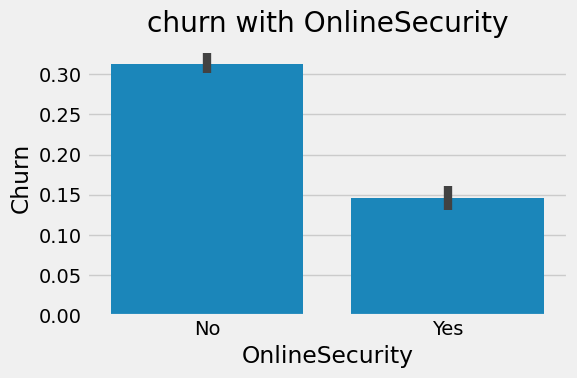

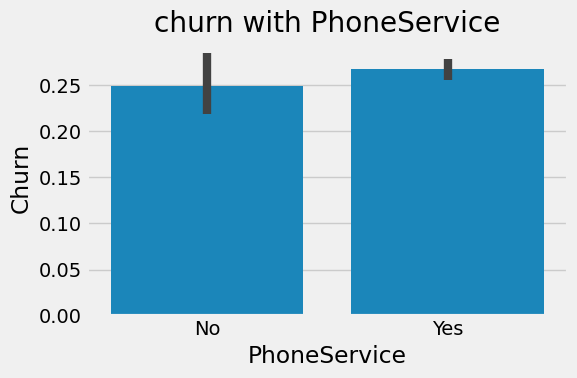

In [37]:
service_col = ['InternetService','StreamingMovies', 'TechSupport','StreamingTV','DeviceProtection', 'OnlineSecurity', 'PhoneService']

for col in service_col:
    plt.figure(figsize=(6,4))
    sns.barplot(data=df, x=col, y="Churn")
    plt.title(f"churn with {col}")
    plt.tight_layout()
    plt.show()

In [38]:
tenure_bins = [0, 12, 24, 36, 48, 60, 72]
tenure_labels=[
    "0-12",
    "12-24",
    "25-36",
    "37-48",
    "49-60",
    "61+"
]

df["tenure_bucket"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    right=True,
    include_lowest=True
)

In [39]:
df["tenure_bucket"]

0        0-12
1       25-36
2        0-12
3       37-48
4        0-12
        ...  
7038    12-24
7039      61+
7040     0-12
7041     0-12
7042      61+
Name: tenure_bucket, Length: 7043, dtype: category
Categories (6, object): ['0-12' < '12-24' < '25-36' < '37-48' < '49-60' < '61+']

In [40]:
tenure_churn_pivot = pd.pivot_table(
    df,
    values="Churn",
    index="tenure_bucket",
    aggfunc="mean"
).reset_index()

In [41]:
tenure_churn_pivot

,tenure_bucket,Churn
0,0-12,0.474382
1,12-24,0.287109
2,25-36,0.216346
3,37-48,0.190289
4,49-60,0.144231
5,61+,0.066098


In [42]:
tenure_churn_pivot["churn_rate_pct"] = (
    tenure_churn_pivot["Churn"] * 100
).round(2)

In [43]:
tenure_churn_pivot

,tenure_bucket,Churn,churn_rate_pct
0,0-12,0.474382,47.44
1,12-24,0.287109,28.71
2,25-36,0.216346,21.63
3,37-48,0.190289,19.03
4,49-60,0.144231,14.42
5,61+,0.066098,6.61


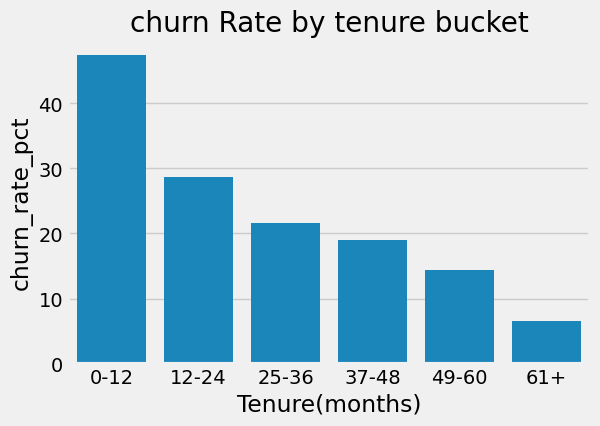

In [44]:
plt.figure(figsize=(6,4))
sns.barplot(data=tenure_churn_pivot, x="tenure_bucket", y="churn_rate_pct")
plt.title("churn Rate by tenure bucket")
plt.xlabel("Tenure(months)")
plt.show()

In [45]:
tenure_count = pd.pivot_table(
    df,
    index="tenure_bucket",
    columns="Contract",
    aggfunc="size"
)

In [46]:
tenure_count

Contract,Month-to-month,One year,Two year
tenure_bucket,,,
0-12,1994,124,68
12-24,737,197,90
25-36,486,250,96
37-48,316,268,178
49-60,234,321,277
61+,108,313,986


Feature Engineering

In [47]:
binary_col = [
    "gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling"
]

df[binary_col] = df[binary_col].replace(
    {"Yes": 1, "No": 0, "Female": 1, "Male":0}
)

In [48]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_bucket
0,1,0,1,0,1,0,No,DSL,No,Yes,...,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0,0-12
1,0,0,0,0,34,1,No,DSL,Yes,No,...,No,No,No,One year,0,Mailed check,56.95,1889.50,0,25-36
2,0,0,0,0,2,1,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1,0-12
3,0,0,0,0,45,0,No,DSL,Yes,No,...,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0,37-48
4,1,0,0,0,2,1,No,Fiber optic,No,No,...,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1,0-12


In [49]:
multi_cat_col = [
    "InternetService", "Contract", "PaymentMethod",
    "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies"
]

df = pd.get_dummies(
    df,
    columns=multi_cat_col,
    drop_first=True
)

In [50]:
bool_cols = df.select_dtypes(include="bool").columns
df[bool_cols] = df[bool_cols].astype(int)

In [51]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,MultipleLines_Yes,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes
0,1,0,1,0,1,0,1,29.85,29.85,0,...,0,1,0,0,0,1,0,0,0,0
1,0,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,1,0,1,0,1,0,0,0
2,0,0,0,0,2,1,1,53.85,108.15,1,...,0,0,1,0,1,1,0,0,0,0
3,0,0,0,0,45,0,0,42.30,1840.75,0,...,0,0,0,0,1,0,1,1,0,0
4,1,0,0,0,2,1,1,70.70,151.65,1,...,0,1,0,0,0,0,0,0,0,0


In [52]:
df["early_tenure"] = (df["tenure"] <= 12).astype(int)

In [53]:
df["early_tenure"] 

0       1
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    1
7041    1
7042    0
Name: early_tenure, Length: 7043, dtype: int64